In [1]:
import pandas as pd
import glob
import numpy as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
paths = glob.glob("../../raw_data/HALO_outputs/*")
for n in range(0,len(paths)):
    df = pd.read_csv(paths[n])
    df['sample_id'] = 'Br'+paths[n].split('Br')[1].split('_DLPFC')[0]
    if n == 0:
        all_df = df
    else:
        all_df = pd.concat([all_df, df], axis = 0)
np.shape(all_df)

(925882, 38)

In [18]:
all_df = all_df[~((all_df['DAPI (DAPI) Positive']==0) & (all_df['MBP (Opal 520) Positive']==1))]
np.shape(all_df)

(919792, 38)

In [36]:
all_df.columns

Index(['Image Location', 'Analysis Region', 'Algorithm Name', 'Object Id',
       'XMin', 'XMax', 'YMin', 'YMax', 'MBP_Oligo', 'HPCAL1_L2_neuron',
       'DAPI (DAPI) Positive', 'DAPI (DAPI) Positive Nucleus',
       'DAPI (DAPI) Nucleus Intensity', 'DAPI (DAPI) Positive Cytoplasm',
       'DAPI (DAPI) Cytoplasm Intensity', 'DAPI (DAPI) Positive Membrane',
       'DAPI (DAPI) Membrane Intensity', 'MBP (Opal 520) Positive',
       'MBP (Opal 520) Positive Nucleus', 'MBP (Opal 520) Nucleus Intensity',
       'MBP (Opal 520) Positive Cytoplasm',
       'MBP (Opal 520) Cytoplasm Intensity',
       'MBP (Opal 520) Positive Membrane', 'MBP (Opal 520) Membrane Intensity',
       'HPCAL1 (Opal 570) Positive', 'HPCAL1 (Opal 570) Positive Nucleus',
       'HPCAL1 (Opal 570) Nucleus Intensity',
       'HPCAL1 (Opal 570) Positive Cytoplasm',
       'HPCAL1 (Opal 570) Cytoplasm Intensity',
       'HPCAL1 (Opal 570) Positive Membrane',
       'HPCAL1 (Opal 570) Membrane Intensity', 'Cell Area (µm²)'

In [37]:
summary = all_df[['DAPI (DAPI) Positive Nucleus', 'MBP (Opal 520) Positive Nucleus', 'sample_id']].groupby(['sample_id']).sum()
summary['DAPI (DAPI) Positive Nucleus'] = summary['DAPI (DAPI) Positive Nucleus'].astype(int)
summary['MBP (Opal 520) Positive Nucleus'] = summary['MBP (Opal 520) Positive Nucleus'].astype(int)
summary['Oligodendrocyte proportion (%)'] = summary['MBP (Opal 520) Positive Nucleus']/summary['DAPI (DAPI) Positive Nucleus']*100

<AxesSubplot:xlabel='sample_id', ylabel='Oligodendrocyte proportion (%)'>

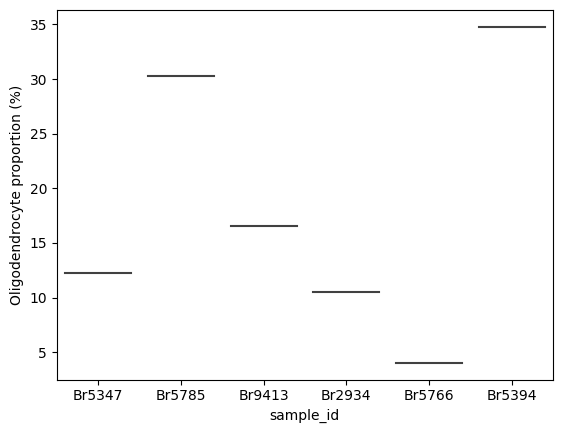

In [38]:
custom_palette = {
    'Br2934': '#4B8D86',  
    'Br5347': '#C3B3A1',  
    'Br5785': '#C3B3A1',  
    'Br5766': '#4B8D86',  
    'Br5394': '#4B8D86',  
    'Br9413': '#C3B3A1',  
}

custom_order = ['Br5347', 'Br5785', 'Br9413', 'Br2934', 'Br5766', 'Br5394']

sns.violinplot(x = summary.index, y = summary['Oligodendrocyte proportion (%)'], palette = custom_palette, order=custom_order)

In [17]:
custom_palette = {
    'Br2934': '#4B8D86',  
    'Br5347': '#C3B3A1',  
    'Br5785': '#C3B3A1',  
    'Br5766': '#4B8D86',  
    'Br5394': '#4B8D86',  
    'Br9413': '#C3B3A1',  
}

custom_order = ['Br5347', 'Br5785', 'Br9413', 'Br2934', 'Br5766', 'Br5394']

## PD oligodendrocytes have lower MBP intensity overall

<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

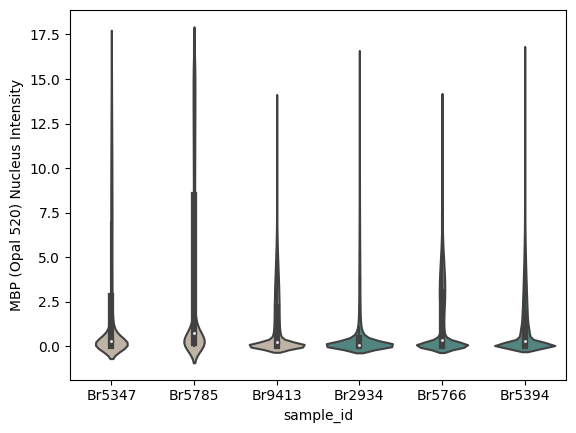

In [19]:
# Overall MBP nucleus intensity signal

sns.violinplot(x = all_df['sample_id'], y = all_df['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

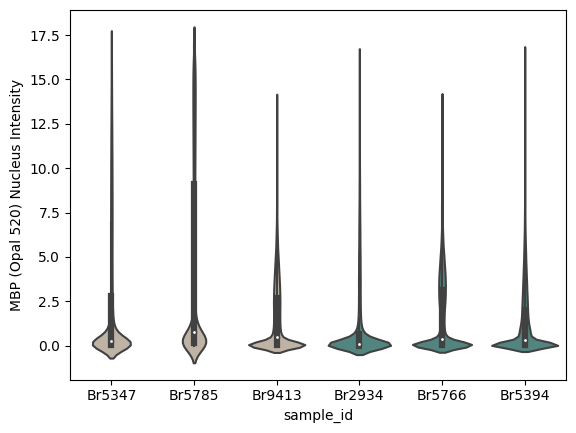

In [20]:
# MBP intensity for cells only

iscell = all_df[all_df['DAPI (DAPI) Positive']==1]
sns.violinplot(x = iscell['sample_id'], y = iscell['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

(162416, 38)


<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

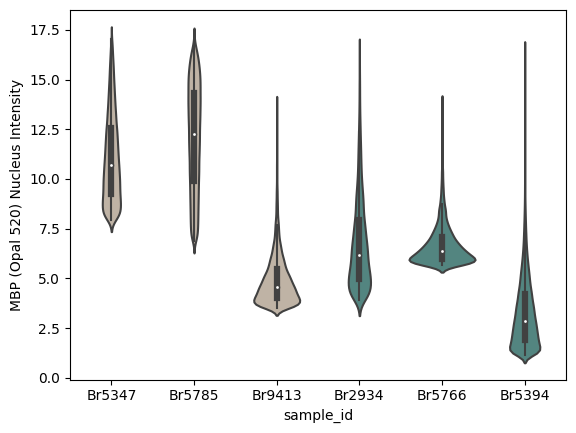

In [21]:
# MBP intensity only for MBP positive cells

iscell = all_df[(all_df['MBP (Opal 520) Positive']==1) & (all_df['DAPI (DAPI) Positive']==1)]
print(np.shape(iscell))
sns.violinplot(x = iscell['sample_id'], y = iscell['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

(168506, 38)


<AxesSubplot:xlabel='sample_id', ylabel='MBP (Opal 520) Nucleus Intensity'>

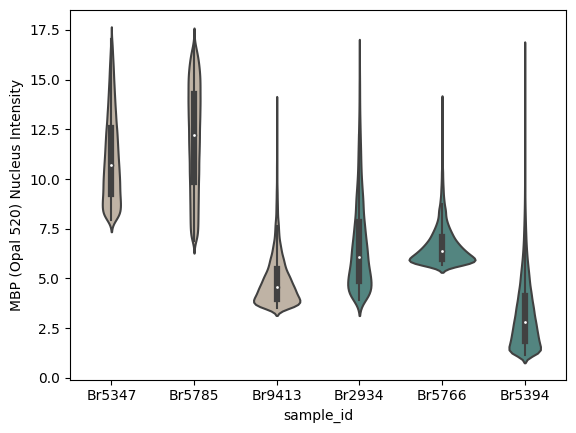

In [22]:
# MBP intensity only for MBP positive dots

iscell = all_df[all_df['MBP (Opal 520) Positive']==1]
print(np.shape(iscell))
sns.violinplot(x = iscell['sample_id'], y = iscell['MBP (Opal 520) Nucleus Intensity'], palette = custom_palette, order=custom_order)

## PD has less % of oligodendrocytes overall

In [40]:
paths = glob.glob("../../raw_data/HALO_outputs/*")
for n in range(0,len(paths)):
    sample_info = []
    df = pd.read_csv(paths[n])
    
    countsMBP = np.shape(df[(df['MBP (Opal 520) Positive']==1) & (df['DAPI (DAPI) Positive']==1)])[0]
    sample_info.append(countsMBP)
    
    countsDAPI = np.shape(df[(df['DAPI (DAPI) Positive']==1)])[0]
    sample_info.append(countsDAPI)
    
    ratio = (countsMBP/countsDAPI)*100
    sample_info.append(ratio)
    
    if n == 0:
        all_results = pd.DataFrame(sample_info, columns = ['Br'+paths[n].split('Br')[1].split('_DLPFC')[0]], index = ['counts MBP', 'counts DAPI', '% MBP+ cells'])
    else:
        results = pd.DataFrame(sample_info, columns = ['Br'+paths[n].split('Br')[1].split('_DLPFC')[0]], index = ['counts MBP', 'counts DAPI', '% MBP+ cells'])
        all_results = pd.concat([all_results, results], axis =1)
all_results = all_results.T

In [41]:
map_sample_type = {
    'Br2934': 'PD',  
    'Br5347': 'Control',  
    'Br5785': 'Control',  
    'Br5766': 'PD',  
    'Br5394': 'PD',  
    'Br9413': 'Control',  
}

all_results['group'] = all_results.index.map(map_sample_type)

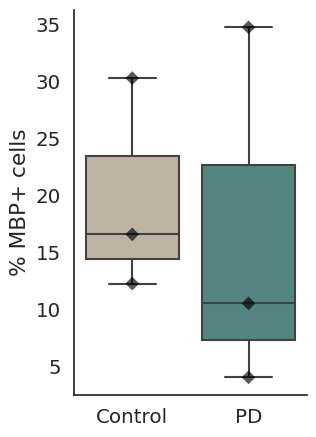

In [64]:
from pylab import rcParams
rcParams['figure.figsize'] = 3,5
sns.set(font_scale=1.3, style = "white")
#sns.set_theme("whitegrid")

custom_palette = {
    'PD': '#4B8D86',  
    'Control': '#C3B3A1',  
}
custom_order = ['Control', 'PD']

sns.boxplot(x = all_results['group'], y = all_results['% MBP+ cells'], palette = custom_palette, order=custom_order)
sns.swarmplot(x = all_results['group'], y = all_results['% MBP+ cells'], color = 'black', marker="D", size = 7, alpha=.65, order=custom_order)
sns.despine(right=True)
plt.xlabel('')
plt.savefig('../../plots/08_validation_oligos/rnascope_total_OGs_group.pdf', dpi = 300, bbox_inches = 'tight')
plt.savefig('../../plots/08_validation_oligos/rnascope_total_OGs_group.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [58]:
all_results[all_results['group']=='PD']['% MBP+ cells']

Br2934    10.530576
Br5766     4.036346
Br5394    34.776293
Name: % MBP+ cells, dtype: float64

In [60]:
from scipy import stats
stats.ttest_ind(all_results[all_results['group']=='PD']['% MBP+ cells'], all_results[all_results['group']=='Control']['% MBP+ cells'])

Ttest_indResult(statistic=-0.30277360658359137, pvalue=0.7771547817297391)